<style>
    /* This is only for styling the notebook for HTML export */
.jp-RenderedHTMLCommon {font: 11pt/1.45 "Times New Roman", Times, serif;}
.jp-Notebook { box-sizing: border-box; max-width: 960px; margin: 32px auto; padding: 0 24px; }
.jp-RenderedHTMLCommon p { text-align: justify; }
.jp-RenderedHTMLCommon h1 { font-size: 20pt; text-align: center; }
.jp-RenderedHTMLCommon h2 { font-size: 12pt; text-align: center; font-variant: small-caps; }
.jp-RenderedHTMLCommon h3, .jp-RenderedHTMLCommon h4, .jp-RenderedHTMLCommon h5 { font-size: 11pt; font-style: italic; text-align: left; }
.jp-RenderedHTMLCommon .nb-author { text-align: center; }
.jp-RenderedHTMLCommon .nb-tabcap { font-size: 9pt; text-align: center; font-variant: small-caps; }
.jp-RenderedHTMLCommon .nb-figcap { font-size: 9pt; text-align: left; }
</style>


# CSCU9YE Metaheuristics for Multi-Resource Workload Allocation



<p class="nb-author">Student ID: 30065980</p>



## Conceptual Understanding


I write this section only to serve as a descriptive understanding of the assignment before moving on to mathematical modeling and computer modeling.


### What decision do we have to make?


- For each candidate model, we need to determine whether it should be **deployed** on the autonomous edge platform
- Determine which **combination of AI models** should be selected to operate together


### Objective: Maximize total utility


- Functional utility: Maximize the combined utility provided by the selected AI models.
- Model selection: Prioritize combinations of models that provide higher overall utility.
- Resource efficiency: Achieve the highest possible utility without exceeding the available hardware resources.


### Constraints


- Each model must either be selected or excluded
- The total resource consumption of selected models must not exceed the available capacity of each resource.
- The combined consumption of RAM, GPU compute, storage, power, and bandwidth, where applicable, must remain within their respective limit.
- All resource constraints must be satisfied simultaneously for a model selection to be feasible.
- A model combination is considered infeasible if it exceeds even one resource capacity.
- The resource requirements and utility values of each AI model are assumed to be fixed and known.


## Problem Formulation

### Mathematical Model: Hardware-Constrained AI Model Selection

The problem is a binary selection problem: each candidate AI model is either deployed or not deployed.


#### 1. Sets, Indices, and Decision Variables

Let $J$ be the set of candidate AI models and $I$ the set of resource types:

$$
J = \{1,2,\ldots,n\}, \qquad I = \{1,2,\ldots,m\}
$$

Here $j \in J$ identifies a model, $i \in I$ identifies a resource, $n$ is the number of candidate models, and $m$ is the number of resource types.

For every model $j$, define the binary decision variable:

$$
x_j =
\begin{cases}
1 & \text{if model } j \text{ is selected}, \\
0 & \text{otherwise}.
\end{cases}
$$

A complete candidate selection is the binary vector $x=(x_1,x_2,\ldots,x_n)$.


#### 2. Parameters

| Symbol | Definition |
|:---|:---|
| $p_j$ | Functional utility provided by model $j$ |
| $r_{i,j}$ | Consumption of resource $i$ by model $j$ |
| $b_i$ | Capacity available for resource $i$ |
| $n$ | Number of candidate models |
| $m$ | Number of resource constraints |

All values are fixed inputs from the corresponding dataset. The datasets do not label the physical resource units; consequently, this notebook refers to Resource 1, Resource 2, and so forth.

| Input | Instance 1 | Instance 2 |
|:---|---:|---:|
| Models ($n$) | 28 | 90 |
| Resources ($m$) | 2 | 5 |
| Capacity for Resource 1 | 500 | 2100 |
| Capacity for Resource 2 | 500 | 1100 |
| Capacity for Resource 3 | — | 3300 |
| Capacity for Resource 4 | — | 3700 |
| Capacity for Resource 5 | — | 3600 |


#### 3. Objective Function

Maximize the total utility of the selected models:

$$
\max f(x)=\sum_{j=1}^{n}p_j x_j
$$

If a model is selected ($x_j=1$), its utility is included; otherwise, it contributes zero.


#### 4. Constraints

For every resource $i$, the total consumption cannot exceed its capacity:

$$
\sum_{j=1}^{n}r_{i,j}x_j \le b_i, \qquad i=1,\ldots,m
$$

All decisions are binary:

$$
x_j \in \{0,1\}, \qquad j=1,\ldots,n
$$

A selection is **feasible** only if *every* resource limit is satisfied. This is the 0–1 multidimensional knapsack model provided in the assignment specification.


#### 5. Instance 1: 28 Models and 2 Resource Limits

Substituting the dataset dimensions and two capacities into the general model gives:

$$
\text{Maximize} \quad f(x)=\sum_{j=1}^{28}p_j x_j \tag{1}
$$

$$
\begin{aligned}
\text{Subject to} \quad & \sum_{j=1}^{28}r_{1,j}x_j \le b_1, \quad b_1=500 \\[5pt]
& \sum_{j=1}^{28}r_{2,j}x_j \le b_2, \quad b_2=500 \\[5pt]
& x_j \in \{0,1\}, \quad j=1,\ldots,28.
\end{aligned}\tag{2}
$$

Both resource constraints must hold for a feasible selection.


#### 6. Instance 2: 90 Models and 5 Resource Limits

The same model applies with five capacities:

$$
\text{Maximize} \quad f(x)=\sum_{j=1}^{90}p_j x_j \tag{3}
$$

$$
\begin{aligned}
\text{Subject to} \quad & \sum_{j=1}^{90}r_{1,j}x_j \le b_1, \quad b_1=2100 \\[5pt]
& \sum_{j=1}^{90}r_{2,j}x_j \le b_2, \quad b_2=1100 \\[5pt]
& \sum_{j=1}^{90}r_{3,j}x_j \le b_3, \quad b_3=3300 \\[5pt]
& \sum_{j=1}^{90}r_{4,j}x_j \le b_4, \quad b_4=3700 \\[5pt]
& \sum_{j=1}^{90}r_{5,j}x_j \le b_5, \quad b_5=3600 \\[5pt]
& x_j \in \{0,1\}, \quad j=1,\ldots,90.
\end{aligned}\tag{4}
$$

The mathematical model is unchanged between the two instances; only the input values and dimensions differ.


## Computer Modelling

### Data Loading

Before implementing a search algorithm, I load the two supplied workload instances. This gives the optimisation code access to the model utilities, resource demands, and capacity limits.

In [327]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

In [328]:
def load_workload_instance(file_path):
    """
    Loads a hardware-constrained workload allocation dataset.
    
    Parameters:
        file_path (str): Path to the dataset plain text file (.txt).
        
    Returns:
        n (int): Number of candidate AI models.
        m (int): Number of hardware resource constraints.
        utilities (np.ndarray): 1D array of shape (n,) containing model utility scores (p_j).
        demands (np.ndarray): 2D array of shape (m, n) containing resource consumption demands (r_{i,j}).
        capacities (np.ndarray): 1D array of shape (m,) containing hardware capacity limits (b_i).
    """
    with open(file_path, 'r') as f:
        tokens = f.read().split()
        
    if not tokens:
        raise ValueError(f"Dataset file at '{file_path}' is empty or invalid.")
        
    n = int(tokens[0])
    m = int(tokens[1])
    idx = 2
    
    # Model utility scores (length n)
    utilities = np.array([float(x) for x in tokens[idx : idx + n]])
    idx += n
    
    # Resource demand matrix (shape m x n)
    demands = np.zeros((m, n))
    for i in range(m):
        demands[i, :] = [float(x) for x in tokens[idx : idx + n]]
        idx += n
        
    # Maximum hardware capacity limits (length m)
    capacities = np.array([float(x) for x in tokens[idx : idx + m]])
    
    return n, m, utilities, demands, capacities


Each dataset file stores its values in this order: the number of models ($n$), the number of resources ($m$), $n$ utility scores, $m \times n$ resource-demand values, and $m$ capacity limits. The `load_workload_instance` function reads this format and returns those values as $n$, $m$, a utility vector, a demand matrix, and a capacity vector. I have kept the function exactly as it was provided in the assignment, as required. The demand matrix has one row per resource and one column per model, so its shape is $(m, n)$.

In [329]:
DATA_DIR = Path("Data")
instance1_path = DATA_DIR / "multi_resource_n28_m2.txt"
instance2_path = DATA_DIR / "multi_resource_n90_m5 (1).txt"

for file_path in (instance1_path, instance2_path):
    if not file_path.is_file():
        raise FileNotFoundError(f"Missing dataset file: {file_path}")

n1, m1, p1, R1, b1 = load_workload_instance(instance1_path)
n2, m2, p2, R2, b2 = load_workload_instance(instance2_path)

In [330]:
print("Instance 1 loaded:", n1, "models and", m1, "resources")
print("Instance 2 loaded:", n2, "models and", m2, "resources")

Instance 1 loaded: 28 models and 2 resources
Instance 2 loaded: 90 models and 5 resources


In [331]:
#Instance 1
print("1. Utility scores shape (p_j)     :", p1.shape)
print("1. Resource demands shape (r_ij)  :", R1.shape)
print("1. Capacity limits (b_i)          :", b1)

1. Utility scores shape (p_j)     : (28,)
1. Resource demands shape (r_ij)  : (2, 28)
1. Capacity limits (b_i)          : [500. 500.]


In [332]:
#Instance 2
print("2. Utility scores shape (p_j)     :", p2.shape)
print("2. Resource demands shape (r_ij)  :", R2.shape)
print("2. Capacity limits (b_i)          :", b2)

2. Utility scores shape (p_j)     : (90,)
2. Resource demands shape (r_ij)  : (5, 90)
2. Capacity limits (b_i)          : [2100. 1100. 3300. 3700. 3600.]


The output shows that Instance 1 contains 28 models and 2 resources, while Instance 2 contains 90 models and 5 resources. Utility scores $p_j$ are stored in one-dimensional arrays. Resource demands $r_{i,j}$ are stored in matrices, with one row per resource and one column per model. Their shapes are $(2, 28)$ and $(5, 90)$.

The capacity vector $b_i$ gives the limit for each resource. Instance 1 has capacities of 500 for both resources. Instance 2 has capacities of 2100, 1100, 3300, 3700, and 3600. A feasible selection must stay within every capacity while maximizing the selected models' total utility.

Each model can be selected or excluded, so $n$ models give $2^n$ possible selections. Instance 1 has 28 models, giving:

$$
2^{28} = 268{,}435{,}456
$$

possible selections.

## Part 1: Baseline Discrete Hill-Climbing Local Search 


I structured the baseline hill climber around three procedures described in [1, Sec. 2.1]: initialisation, modification, and assessment and selection. These procedures determine how the algorithm constructs a feasible starting solution, explores alternative model combinations, and decides which improvement to accept. For the modification procedure, I chose bit flips and one-for-one swaps to explore the neighbourhood, using 2 method forms the overall best-improvement strategy to select the next solution.

### 1.2 Initialisation



In [333]:
def random_feasible_start(utilities, demands, capacities):
    """Build a feasible selection by checking models in random order."""
    selection = np.zeros(len(utilities), dtype=np.int8)
    resource_usage = np.zeros(len(capacities), dtype=float)

    for model in np.random.permutation(len(utilities)):
        proposed_usage = resource_usage + demands[:, model]
        if np.all(proposed_usage <= capacities + 1e-9):
            selection[model] = 1
            resource_usage = proposed_usage

    return selection

I use the function `random_feasible_start()` to create a feasible starting selection for hill climbing before the search begins. It starts with all models excluded, then uses `np.random.permutation()` to shuffle their order so models listed first do not always get priority. It adds a model only when its resource demands fit within every capacity. The `1e-9` tolerance allows for tiny floating-point rounding differences, not meaningful extra resource use.

In [334]:
initial_solution = random_feasible_start(p1, R1, b1)
initial_utility = float(p1 @ initial_solution)
initial_resource_usage = R1 @ initial_solution

print("Initial selection:", initial_solution)
print("Initial utility:", initial_utility)
print("Resource use:", initial_resource_usage)
print("Feasible:", np.all(initial_resource_usage <= b1 + 1e-9))

Initial selection: [1 1 0 0 1 0 0 0 1 1 1 1 1 1 0 1 1 1 1 0 0 1 1 1 1 1 1 0]
Initial utility: 66824.0
Resource use: [500. 492.]
Feasible: True


The output shows the initial selection of 28 models. Each `1` marks a selected model, and each `0` marks an excluded model. The selected models have a total utility of 66,824 and use 500 units of Resource 1 and 492 units of Resource 2. These amounts are within the respective capacities of 500 units each, so the starting selection is feasible.

### 1.3 Modification Procedure


In [335]:
def generate_feasible_neighbors(selection, demands, capacities):
    """Yield feasible one-bit flips and one-for-one swaps."""
    selected = np.flatnonzero(selection)
    unselected = np.flatnonzero(selection == 0)

    for model in range(len(selection)):
        candidate = selection.copy()
        candidate[model] = 1 - candidate[model]
        if np.all(demands @ candidate <= capacities + 1e-9):
            yield candidate

    for remove_model in selected:
        for add_model in unselected:
            candidate = selection.copy()
            candidate[remove_model] = 0
            candidate[add_model] = 1
            if np.all(demands @ candidate <= capacities + 1e-9):
                yield candidate


The function creates neighbouring selections using bit flips and one-for-one swaps. `np.flatnonzero()` identifies the selected and unselected models. For a bit flip, the function copies the current selection and changes one value with `candidate[model] = 1 - candidate[model]`, leaving the original selection unchanged. It yields the candidate only when `np.all(demands @ candidate <= capacities + 1e-9)` confirms that every resource limit is satisfied.

For a swap, the function removes one selected model and adds one unselected model. The function copies the current selection first, so the swap changes only the candidate and leaves the original unchanged. Removing a model frees its resource use, which can make a replacement feasible when adding that model directly would exceed a capacity. Combining swaps and bit-flip require more candidate checks, but allow the search to consider higher-utility replacements.

In [336]:
feasible_neighbors = list(generate_feasible_neighbors(initial_solution, R1, b1))
print("Feasible neighbouring selections:", len(feasible_neighbors))

Feasible neighbouring selections: 56


The code stores the feasible neighbouring selections returned by `generate_feasible_neighbors()`, using `initial_solution`, `R1`, and `b1` as inputs. The function checks each candidate against the resource limits. The output, 56, is the number of feasible candidate selections; it does not mean that 56 models have been selected. The aim is to maximise utility. The next section explains hill climbing's 'exploitation step, where these candidates are assessed and one is selected.

### 1.4 Assessment and Selection


In [337]:
def assess_and_select(current_solution, candidates, utilities):
    """Return the highest-utility strict improvement, if one exists."""
    current_utility = float(utilities @ current_solution)
    best_solution = current_solution.copy()
    best_utility = current_utility

    for candidate in candidates:
        candidate_utility = float(utilities @ candidate)
        if candidate_utility > best_utility:
            best_solution = candidate.copy()
            best_utility = candidate_utility

    return best_solution, best_utility, best_utility > current_utility

The `assess_and_select()` function evaluates the feasible neighbours generated by the modification procedure and decides which solution to keep. It calculates the current utility with `utilities @ current_solution`, which multiplies each model's utility by its binary selection value and sums the results. This applies objective function (1).

The `for` loop examines each feasible neighbour and tracks the one with the highest utility. The condition `candidate_utility > best_utility` accepts only a strict improvement, so a candidate with equal utility is not selected.

The function returns three values: the best solution, its utility, and a Boolean indicating whether an improvement was found. The expression `best_utility > current_utility` returns `True` when a candidate improves on the starting utility and `False` otherwise. The hill-climbing loop uses this result to decide whether another iteration is needed.

In [338]:
next_solution, next_utility, improved = assess_and_select(initial_solution, feasible_neighbors, p1)
assert next_utility >= initial_utility
print("Current utility:", initial_utility)
print("Selected utility:", next_utility)
print("Improvement found:", improved)

Current utility: 66824.0
Selected utility: 83476.0
Improvement found: True


I test the function using the feasible neighbours generated earlier. The assertion `next_utility >= initial_utility` checks that the selected solution has not reduced utility. The function uses the feasible neighbours from the modification procedure and the initial solution. The output shows utility increasing from 66,824 to 83,476, with `improved` set to `True`. These results come from the current random seed, 42. The selected utility is expected to be the better feasible solution, not the best. The next step is to evaluate this design across multiple independent runs by combining the procedures into one algorithm and running it with different seeds.

### The Feasibility-Preserving Best-Improvement Hill Climbing Algorithm

The section title reflects three features of the algorithm. It preserves feasibility by rejecting infeasible neighbours before assessment, then uses best-improvement selection to choose the feasible neighbour with the greatest utility gain. Bit flips and one-for-one swaps explore alternatives until no feasible neighbour improves the current solution

In [339]:
def hill_climb(initial_solution, utilities, demands, capacities):
    solution = initial_solution.copy()
    utility = float(utilities @ solution)

    utility_history = [utility]
    solution_history = [solution.copy()]
    accepted_moves = 0

    while True:
        
        neighbours = generate_feasible_neighbors(solution, demands, capacities)
        candidate, candidate_utility, improved = assess_and_select(solution, neighbours, utilities)

        if not improved:
            break

        solution = candidate
        utility = candidate_utility
        accepted_moves += 1
        utility_history.append(utility)
        solution_history.append(solution.copy())

    return solution, utility, accepted_moves, utility_history, solution_history

At each iteration, `hill_climb()` generates feasible neighbours and uses `assess_and_select()` to choose the highest-utility neighbour that improves on the current solution. It repeats until no neighbour offers an improvement, then returns the final selection and search history. The accepted-move count shows how many improvements were made before the search stopped. This is a local optimum within the neighbourhood examined; better solutions may exist outside it, so the search does not guarantee a global optimum.

In [340]:
final_solution, final_utility, accepted_moves, utility_history, solution_history = hill_climb(initial_solution, p1, R1, b1)
print("Initial utility:", utility_history[0])
print("Final utility:", final_utility)
print("Accepted moves:", accepted_moves)
print("Final selection:", final_solution)
print("Resource consumption:", R1 @ final_solution)
print("Feasible:", np.all(R1 @ final_solution <= b1))

Initial utility: 66824.0
Final utility: 88927.0
Accepted moves: 4
Final selection: [0 0 0 0 0 1 1 1 1 1 1 1 1 1 1 0 1 1 1 0 0 1 1 1 1 1 1 0]
Resource consumption: [490. 493.]
Feasible: True


The output shows that the hill climber algorithm increased the initial utility from 66,824 to 88,927, achieving an improvement of 22,103 (33.1%) through four accepted moves. The final selection consumes 490 units of Resource 1 and 493 units of Resource 2, corresponding to 98% and 98.6% of their respective capacities. The manual calculations are:

$$
\begin{aligned}
\text{Resource 1 utilisation} &= \frac{490}{500} \times 100 = 98\%, \\
\text{Resource 2 utilisation} &= \frac{493}{500} \times 100 = 98.6\%.
\end{aligned}
$$ The feasibility check returns True, confirming that the final solution satisfies both resource constraints

### 1.5 Repeated Independent Runs


In [341]:
N_RUNS = 30
hill_climb_runs = []

for run in range(N_RUNS):
    initial = random_feasible_start(p1, R1, b1)

    solution, utility, moves, utility_history, solution_history = hill_climb(initial, p1, R1, b1)

    resource_usage = R1 @ solution
    assert np.all(resource_usage <= b1 + 1e-9)

    hill_climb_runs.append({
        "run": run + 1,
        "initial_utility": utility_history[0],
        "final_utility": utility,
        "accepted_moves": moves,
        "resource_usage": resource_usage,
        "utility_history": utility_history,
        "solution_history": solution_history
    })

    print(f"Run {run + 1}: {utility_history[0]:.0f} → {utility:.0f}, {moves} moves")

Run 1: 99282 → 106380, 1 moves
Run 2: 45381 → 118009, 8 moves
Run 3: 70259 → 110440, 11 moves
Run 4: 93314 → 102292, 2 moves
Run 5: 92346 → 124430, 6 moves
Run 6: 81800 → 84552, 1 moves
Run 7: 73037 → 79767, 2 moves
Run 8: 110221 → 123669, 4 moves
Run 9: 59037 → 118750, 5 moves
Run 10: 74199 → 113286, 2 moves
Run 11: 99387 → 111662, 2 moves
Run 12: 97517 → 100472, 3 moves
Run 13: 84982 → 90460, 4 moves
Run 14: 88320 → 111917, 4 moves
Run 15: 109531 → 113316, 1 moves
Run 16: 91469 → 104464, 5 moves
Run 17: 77427 → 129183, 7 moves
Run 18: 80687 → 119960, 8 moves
Run 19: 67820 → 102737, 6 moves
Run 20: 74757 → 116301, 7 moves
Run 21: 110273 → 118596, 5 moves
Run 22: 73917 → 90125, 6 moves
Run 23: 69544 → 123910, 7 moves
Run 24: 53322 → 119750, 9 moves
Run 25: 78155 → 104628, 5 moves
Run 26: 61179 → 122062, 5 moves
Run 27: 88102 → 122564, 6 moves
Run 28: 75789 → 79767, 2 moves
Run 29: 102292 → 102292, 0 moves
Run 30: 102647 → 104037, 1 moves


I run the hill climber 30 times to see how starting selections affect final utility. `N_RUNS = 30` sets the run count. NumPy is seeded with 42 earlier in the notebook, so the sequence is reproducible when the notebook is run from the beginning. Each run creates a new feasible starting selection and applies hill climbing; an `assert` checks that the final selection respects both resource limits. I store the initial and final utilities, accepted moves, resource use, and search histories in `hill_climb_runs` to compare runs and produce convergence and resource-utilisation plots.


In [342]:
initial_utilities = np.array([run["initial_utility"] for run in hill_climb_runs])
final_utilities = np.array([run["final_utility"] for run in hill_climb_runs])
moves = np.array([run["accepted_moves"] for run in hill_climb_runs])
resource_usage = np.array([run["resource_usage"] for run in hill_climb_runs])

print("Hill-Climbing Performance Summary")
print(f"Number of runs:       {N_RUNS}")\

# Solution quality: measure the utility achieved and improvement from initialisation
print(f"Mean initial utility: {initial_utilities.mean():,.2f}")
print(f"Mean final utility:   {final_utilities.mean():,.2f}")
print(f"Mean improvement:     {(final_utilities - initial_utilities).mean():,.2f}")
print(f"Median final utility: {np.median(final_utilities):,.2f}")
print(f"Best final utility:   {final_utilities.max():,.0f}")
print(f"Worst final utility:  {final_utilities.min():,.0f}")

# Consistency: measure variation in final utility across different runs
print(f"Standard deviation:   {final_utilities.std(ddof=1):,.2f}")

# Search behaviour: measure accepted improvements and final resource utilisation
print(f"Mean accepted moves:  {moves.mean():.2f}")
print(f"Mean Resource 1 use:  {100 * np.mean(resource_usage[:, 0] / b1[0]):.2f}%")
print(f"Mean Resource 2 use:  {100 * np.mean(resource_usage[:, 1] / b1[1]):.2f}%")

Hill-Climbing Performance Summary
Number of runs:       30
Mean initial utility: 82,866.43
Mean final utility:   108,992.60
Mean improvement:     26,126.17
Median final utility: 111,789.50
Best final utility:   129,183
Worst final utility:  79,767
Standard deviation:   13,556.34
Mean accepted moves:  4.50
Mean Resource 1 use:  95.87%
Mean Resource 2 use:  99.12%


I use these metrics to assess **solution quality**, **consistency**, and **search behaviour**. Since the objective is to maximise total utility (1), initial and final utilities show improvement. The mean and median describe typical performance across 30 runs, while the best, worst, and standard deviation show variation between starting selections and the local optima they reach.

Mean accepted moves show how many improvements occur before the search stops. Resource utilisation shows how much of each capacity the final selections use; neither more moves nor higher resource use necessarily means a better solution. Across the runs, mean final utility was 108,992.60, with a best of 129,183 and a worst of 79,767. The standard deviation was 13,556.34. Run 3 reached 110,440 after 11 accepted moves; Run 6 reached 84,552 after one. These results show that starting selections can lead to different local optima. The metrics also provide a baseline for interpreting convergence curves and assessing future changes to the search method.

### 1.6 Convergence Curves 

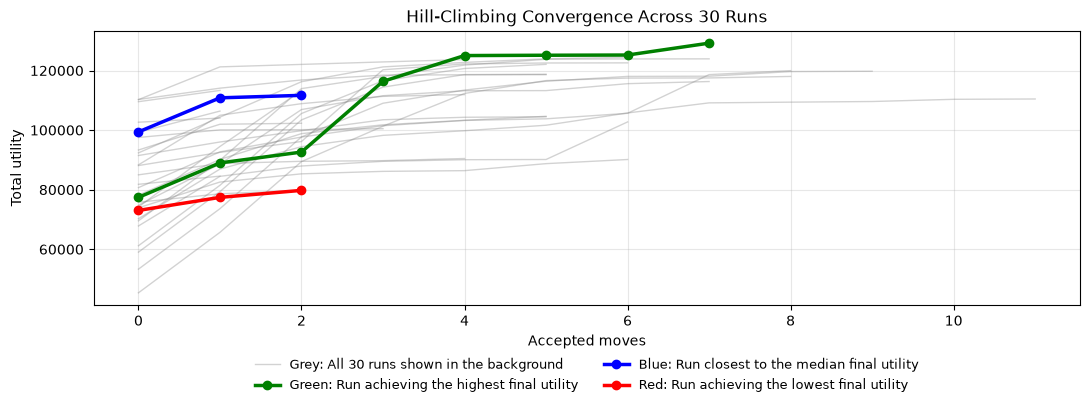

In [343]:
finals = np.array([run["final_utility"] for run in hill_climb_runs])
best = int(np.argmax(finals))
worst = int(np.argmin(finals))
median = int(np.argmin(np.abs(finals - np.median(finals))))

fig, ax = plt.subplots(figsize=(11, 5.5))

for run_index, run in enumerate(hill_climb_runs):
    history = run["utility_history"]
    label = "Grey: All 30 runs shown in the background" if run_index == 0 else "_nolegend_"
    ax.plot(range(len(history)), history, color="grey", alpha=0.35, linewidth=1, label=label)

highlights = [(best, "Green: Run achieving the highest final utility", "green"), (median, "Blue: Run closest to the median final utility", "blue"), (worst, "Red: Run achieving the lowest final utility", "red"),]
for index, label, color in highlights:
    history = hill_climb_runs[index]["utility_history"]
    ax.plot(range(len(history)), history, marker="o", color=color,linewidth=2.5, label=label, zorder=3)

ax.set_xlabel("Accepted moves")
ax.set_ylabel("Total utility")
ax.set_title("Hill-Climbing Convergence Across 30 Runs")
ax.grid(alpha=0.3)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=2, frameon=False, fontsize=9)
fig.tight_layout(rect=(0, 0.20, 1, 1))
plt.show()

As the number presented in the metrics summary section. Across the 30 runs, utility generally rises as the hill climber accepts improvements, but final scores differ because the runs start from different initial feasible selections. The horizontal axis counts accepted moves, and the vertical axis shows total utility. Grey lines show all runs; green marks the run with the highest final utility, blue the run closest to the median, and red the lowest. Each line stops when no feasible neighbour improves its selection.

## Part 2 — Advanced Population-Based Metaheuristic

With regard to Instance 2, the data-loading output shows a significantly larger search space. The model-selection decision involves 90 binary models and five resource constraints. The number of possible selections is calculated as follows:

$$
2^n -> 2^{90} \approx 1.23 \times 10^{27}. 
$$

That is about 1.23 octillion possible binary combinations. For this section, I apply a variant of the genetic algorithm. My design choice is a Diversity-Preserving Steady-State Genetic Algorithm (DP-SSGA). My goal is inclusion: I want separate niches to survive, not only to return the single best selection. If one elite region takes over the population, the search returns one solution and its copies. The risk is higher here because there is one objective and five resource constraints. 

In Genetic Algorithm, The repair layer pulls children toward the same boundary region, so the population can collapse early and the search can stall. In practice, an engineer or manager may also want a diverse set of good configurations, not one fast path. To address this, I add a crowding layer based on Hamming distance, implemented as restricted tournament selection. Each child competes only with the most similar individual in a random window of 20, and replaces it only if it is better. This keeps competition local and reduces the risk of premature convergence.

### 2.1 Diversity-Preserving Steady-State Genetic Algorithm

In [344]:
GA_POP_SIZE = 90

First 

In [345]:
def initial_population(utilities, demands, capacities, size):
    n_models = len(utilities)
    population = np.zeros((size, n_models), dtype=np.int8)

    for i in range(size):
        usage = np.zeros(len(capacities), dtype=float)

        for j in np.random.permutation(n_models):
            proposed_usage = usage + demands[:, j]
            if np.all(proposed_usage <= capacities):
                population[i, j] = 1
                usage = proposed_usage

    return population

In [ ]:
initial_ga_population = initial_population(p2, R2, b2, GA_POP_SIZE)
assert initial_ga_population.shape == (GA_POP_SIZE, n2)
assert np.all((initial_ga_population == 0) | (initial_ga_population == 1))
assert np.all(initial_ga_population @ R2.T <= b2 + 1e-9)

print("Population shape:", initial_ga_population.shape)
print("Distinct configurations:", len(np.unique(initial_ga_population, axis=0)))
print("Feasible configurations:", GA_POP_SIZE)

Population shape: (90, 90)
Distinct configurations: 90
Feasible configurations: 90


## 2.2 Initial population


## References

[1] S. Luke, *Essentials of Metaheuristics*, 2nd ed. Lulu, 2013. [Online]. Available: https://people.cs.gmu.edu/~sean/book/metaheuristics/